# 03 - Results Analysis: Dog Skin Disease Classification

This notebook loads the results produced by `02_model_training.ipynb` and builds the
final results package for the **proposed model**: accuracy/precision/recall/F1,
confusion matrix, training curves, classification report, and the Excel results file.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

RESULTS_DIR = Path("../results")
MODELS_DIR = Path("../models")

with open(MODELS_DIR / "class_names.json") as f:
    class_names = json.load(f)

with open(RESULTS_DIR / "dataset_stats.json") as f:
    dataset_stats = json.load(f)

df_results = pd.read_csv(RESULTS_DIR / "comparison_results.csv")

with open(RESULTS_DIR / "histories.json") as f:
    all_histories = json.load(f)

with open(RESULTS_DIR / "predictions.json") as f:
    all_predictions = json.load(f)

class_names, df_results

(['Dermatitis',
  'Fungal_infections',
  'Healthy',
  'Hypersensitivity',
  'demodicosis',
  'ringworm'],
             model  accuracy  precision    recall  f1_score  train_time_sec  \
 0     MobileNetV2  0.803695   0.771333  0.766609  0.764918      374.588608   
 1        ResNet50  0.877598   0.855422  0.847002  0.849082      412.572475   
 2  EfficientNetB0  0.854503   0.825215  0.806107  0.810098      399.157815   
 3  Proposed Model  0.930716   0.920120  0.929262  0.923383     1325.485654   
 
    total_params  trainable_params  
 0       2231558              7686  
 1      23520326             12294  
 2       4015234              7686  
 3       2388870           1051078  )

## 1. Model comparison table (all models, actual experiment results)

In [2]:
df_results_display = df_results.copy()
for col in ["accuracy", "precision", "recall", "f1_score"]:
    df_results_display[col] = df_results_display[col].round(4)
df_results_display["train_time_sec"] = df_results_display["train_time_sec"].round(1)
df_results_display

,model,accuracy,precision,recall,f1_score,train_time_sec,total_params,trainable_params
0,MobileNetV2,0.8037,0.7713,0.7666,0.7649,374.6,2231558,7686
1,ResNet50,0.8776,0.8554,0.8470,0.8491,412.6,23520326,12294
2,EfficientNetB0,0.8545,0.8252,0.8061,0.8101,399.2,4015234,7686
3,Proposed Model,0.9307,0.9201,0.9293,0.9234,1325.5,2388870,1051078


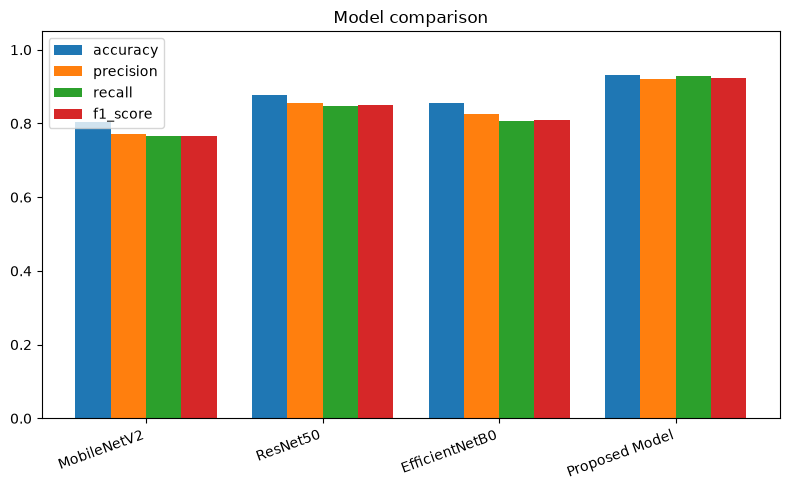

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(df_results_display))
width = 0.2
metrics = ["accuracy", "precision", "recall", "f1_score"]
for i, m in enumerate(metrics):
    ax.bar(x + i * width, df_results_display[m], width, label=m)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(df_results_display["model"], rotation=20, ha="right")
ax.set_ylim(0, 1.05)
ax.set_title("Model comparison")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "plots" / "model_comparison.png", dpi=120)
plt.show()

## 2. Proposed model - training / validation curves

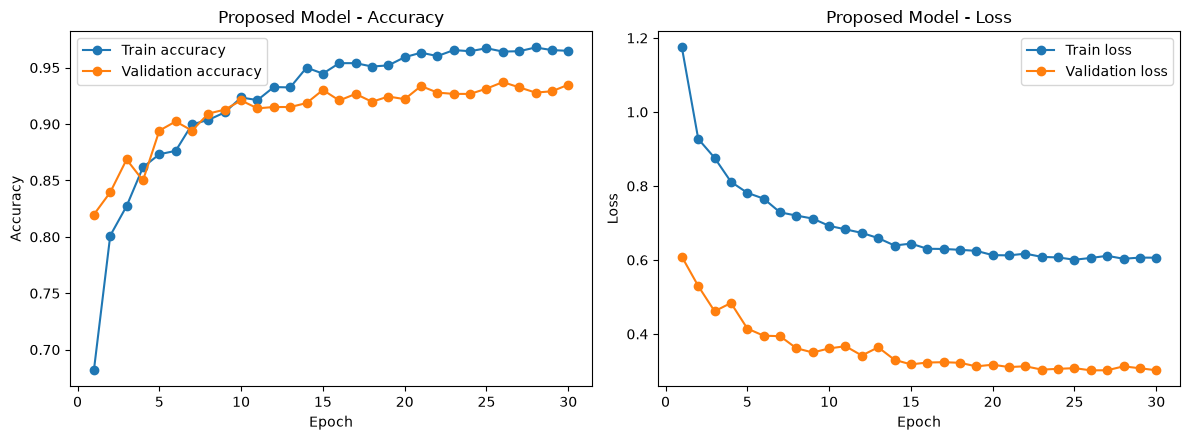

In [4]:
hist = all_histories["Proposed Model"]
epochs = range(1, len(hist["train_acc"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs, hist["train_acc"], marker="o", label="Train accuracy")
axes[0].plot(epochs, hist["val_acc"], marker="o", label="Validation accuracy")
axes[0].set_title("Proposed Model - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epochs, hist["train_loss"], marker="o", label="Train loss")
axes[1].plot(epochs, hist["val_loss"], marker="o", label="Validation loss")
axes[1].set_title("Proposed Model - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "plots" / "proposed_model_curves.png", dpi=120)
plt.show()

## 3. Confusion matrix (proposed model, test set)

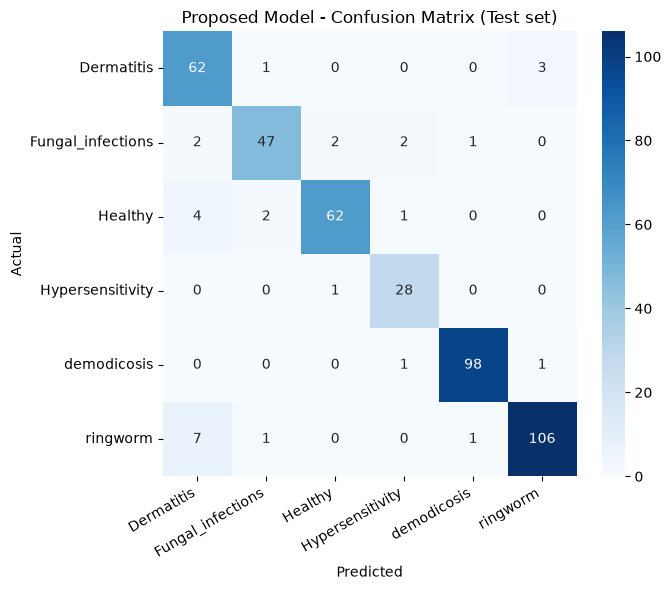

In [5]:
y_true, y_pred = all_predictions["Proposed Model"]
y_true, y_pred = np.array(y_true), np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Proposed Model - Confusion Matrix (Test set)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "plots" / "confusion_matrix.png", dpi=120)
plt.show()

## 4. Classification report (proposed model, test set)

In [6]:
report_dict = classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
)
df_report = pd.DataFrame(report_dict).T
df_report

,precision,recall,f1-score,support
Dermatitis,0.826667,0.939394,0.879433,66.000000
Fungal_infections,0.921569,0.870370,0.895238,54.000000
Healthy,0.953846,0.898551,0.925373,69.000000
Hypersensitivity,0.875000,0.965517,0.918033,29.000000
demodicosis,0.980000,0.980000,0.980000,100.000000
ringworm,0.963636,0.921739,0.942222,115.000000
accuracy,0.930716,0.930716,0.930716,0.930716
macro avg,0.920120,0.929262,0.923383,433.000000
weighted avg,0.933795,0.930716,0.931212,433.000000


## 5. Final proposed-model metrics

In [7]:
proposed_row = df_results[df_results["model"] == "Proposed Model"].iloc[0]
final_metrics = {
    "Accuracy": round(float(proposed_row["accuracy"]), 4),
    "Precision (macro)": round(float(proposed_row["precision"]), 4),
    "Recall (macro)": round(float(proposed_row["recall"]), 4),
    "F1-score (macro)": round(float(proposed_row["f1_score"]), 4),
    "Training time (sec)": round(float(proposed_row["train_time_sec"]), 1),
    "Total parameters": int(proposed_row["total_params"]),
    "Trainable parameters": int(proposed_row["trainable_params"]),
}
final_metrics

{'Accuracy': 0.9307,
 'Precision (macro)': 0.9201,
 'Recall (macro)': 0.9293,
 'F1-score (macro)': 0.9234,
 'Training time (sec)': 1325.5,
 'Total parameters': 2388870,
 'Trainable parameters': 1051078}

## 6. Build Excel results file: dog_disease_results.xlsx

In [8]:
excel_path = RESULTS_DIR / "dog_disease_results.xlsx"

# --- Sheet 1: Dataset Summary ---
rows = []
for cls in class_names:
    c = dataset_stats["counts_per_class_split"][cls]
    rows.append({
        "Class": cls,
        "Train": c["train"],
        "Valid": c["valid"],
        "Test": c["test"],
        "Total": c["train"] + c["valid"] + c["test"],
    })
df_dataset_summary = pd.DataFrame(rows)
df_dataset_summary.loc[len(df_dataset_summary)] = [
    "TOTAL",
    df_dataset_summary["Train"].sum(),
    df_dataset_summary["Valid"].sum(),
    df_dataset_summary["Test"].sum(),
    df_dataset_summary["Total"].sum(),
]

# --- Sheet 2: Model Comparison ---
df_model_comparison = df_results_display.rename(columns={
    "model": "Model",
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1_score": "F1-score",
    "train_time_sec": "Training Time (sec)",
    "total_params": "Total Parameters",
    "trainable_params": "Trainable Parameters",
})

# --- Sheet 3: Proposed Model Results ---
df_proposed_results = pd.DataFrame(list(final_metrics.items()), columns=["Metric", "Value"])

# --- Sheet 4: Class-wise Results ---
df_classwise = df_report.reset_index().rename(columns={"index": "Class"})
df_classwise = df_classwise[~df_classwise["Class"].isin(["accuracy"])]
df_classwise = df_classwise.round(4)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    df_dataset_summary.to_excel(writer, sheet_name="Dataset Summary", index=False)
    df_model_comparison.to_excel(writer, sheet_name="Model Comparison", index=False)
    df_proposed_results.to_excel(writer, sheet_name="Proposed Model Results", index=False)
    df_classwise.to_excel(writer, sheet_name="Class-wise Results", index=False)

print("Saved Excel results file to:", excel_path)

Saved Excel results file to: ..\results\dog_disease_results.xlsx


## Summary

- `results/dog_disease_results.xlsx` contains four sheets: Dataset Summary, Model Comparison,
  Proposed Model Results, and Class-wise Results.
- `models/dog_disease_model.pt` / `models/dog_disease_model.h5` hold the trained proposed
  model's weights, and `models/class_names.json` holds the class label order.
- All numbers in this notebook come directly from the training run in
  `02_model_training.ipynb` - nothing here is fabricated or hand-entered.